<a href="https://colab.research.google.com/github/Shubh009-DataAnalyst/Ad_funnel__cleaning-and-eda/blob/main/Ad_funnel_cleaning_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Data loading
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("/content/ad_campaign_funnel_raw_v2.csv")
print(df.shape)
df.head()

(5295, 15)


,date,campaign_id,campaign_name,platform,campaign_type,target_audience,creative_type,device,impressions,clicks,landing_page_views,add_to_cart,purchases,ad_spend_inr,revenue_inr
0,2025-07-01,C01,Google Search - Brand,Google Ads,Search,Existing Customers,Text,Desktop,2454,203,184.0,49,5,3023.62,11907.38
1,2025-07-01,C01,Google Search - Brand,Google Ads,Search,Existing Customers,Text,Mobile,4126,283,250.0,79,26,5052.41,47610.71
2,2025-07-01,C01,Google Search - Brand,Google Ads,Search,Existing Customers,Text,Tablet,877,76,61.0,20,8,1000.61,16240.52
3,2025-07-01,C02,Google Search - Generic,Google Ads,Search,New Users,Text,Desktop,5553,284,238.0,64,12,4701.16,22832.32
4,2025-07-01,C02,Google Search - Generic,Google Ads,Search,New Users,Text,Mobile,8017,263,214.0,60,13,7889.80,29020.77


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5295 entries, 0 to 5294
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   date                5295 non-null   object 
 1   campaign_id         5295 non-null   object 
 2   campaign_name       5295 non-null   object 
 3   platform            5295 non-null   object 
 4   campaign_type       5295 non-null   object 
 5   target_audience     5295 non-null   object 
 6   creative_type       5295 non-null   object 
 7   device              5295 non-null   object 
 8   impressions         5295 non-null   int64  
 9   clicks              5295 non-null   int64  
 10  landing_page_views  5281 non-null   float64
 11  add_to_cart         5295 non-null   int64  
 12  purchases           5295 non-null   int64  
 13  ad_spend_inr        5295 non-null   float64
 14  revenue_inr         5286 non-null   float64
dtypes: float64(3), int64(4), object(8)
memory usage: 620.6+

In [ ]:
# Duplicates and Missing values

print("Duplicates:", df.duplicated().sum())
df.isnull().sum()

Duplicates: 18


,0
date,0
campaign_id,0
campaign_name,0
platform,0
campaign_type,0
target_audience,0
creative_type,0
device,0
impressions,0
clicks,0


In [ ]:
df["platform"].value_counts()

,count
platform,
Google Ads,1662
Facebook,1108
Instagram,916
Email,554
LinkedIn,553
YouTube,495
instagram,3
linkedin,2
facebook,2


In [ ]:
# Text columns check

print(df["device"].unique())
print(df["campaign_type"].unique())
print(df["target_audience"].unique())

['Desktop' 'Mobile' 'Tablet']
['Search' 'Shopping' 'Social' 'Retargeting' 'Video' 'Email' 'Influencer']
['Existing Customers' 'New Users' 'Website Visitors' 'Professionals'
 'Lookalike']


In [ ]:
df.describe()

,impressions,clicks,landing_page_views,add_to_cart,purchases,ad_spend_inr,revenue_inr
count,5295.000000,5295.000000,5281.000000,5295.000000,5295.000000,5295.000000,5286.000000
mean,6400.920680,137.816808,108.696648,31.261568,6.370727,3798.550735,11505.646078
std,6263.626047,98.855923,80.883617,25.625646,6.198048,3443.019212,11459.086248
min,422.000000,1.000000,1.000000,0.000000,0.000000,274.640000,0.000000
25%,2028.500000,52.000000,40.000000,11.000000,2.000000,1409.040000,3267.065000
50%,4189.000000,123.000000,95.000000,26.000000,5.000000,2818.120000,8103.055000
75%,8707.000000,203.000000,159.000000,45.000000,9.000000,5097.530000,16541.470000
max,38971.000000,604.000000,510.000000,192.000000,48.000000,31855.640000,92357.470000


In [ ]:
# Removing Duplicates
df = df.drop_duplicates()
print(df.shape)

(5277, 15)


In [ ]:
# Fixing Platform name

df["platform"] = df["platform"].replace({"facebook": "Facebook",
                                         "instagram": "Instagram",
                                         "linkedin": "LinkedIn"})
df["platform"].value_counts()

,count
platform,
Google Ads,1656
Facebook,1104
Instagram,918
Email,552
LinkedIn,552
YouTube,495


In [ ]:
# fix datatype of date column
df["date"] = pd.to_datetime(df["date"])
df["date"].dtype

dtype('<M8[ns]')

In [ ]:
# Missing values
df[df.isnull().any(axis=1)]

,date,campaign_id,campaign_name,platform,campaign_type,target_audience,creative_type,device,impressions,clicks,landing_page_views,add_to_cart,purchases,ad_spend_inr,revenue_inr
210,2025-07-09,C06,Instagram Reels,Instagram,Video,New Users,Video,Mobile,21329,309,NaN,47,5,7309.33,7718.04
234,2025-07-10,C06,Instagram Reels,Instagram,Video,New Users,Video,Mobile,17142,272,NaN,41,4,5609.39,5515.14
311,2025-07-13,C09,Email Newsletter Ads,Email,Email,Existing Customers,Image,Tablet,882,51,43.0,12,1,461.30,NaN
392,2025-07-17,C02,Google Search - Generic,Google Ads,Search,New Users,Text,Tablet,1787,56,NaN,14,2,1620.55,3048.04
439,2025-07-19,C02,Google Search - Generic,Google Ads,Search,New Users,Text,Mobile,9980,359,NaN,59,13,9422.40,23998.93
558,2025-07-23,C08,YouTube Pre-roll,YouTube,Video,New Users,Video,Desktop,13743,100,NaN,15,1,3078.18,2081.46
598,2025-07-25,C02,Google Search - Generic,Google Ads,Search,New Users,Text,Desktop,5556,257,214.0,61,8,4900.84,NaN
649,2025-07-27,C01,Google Search - Brand,Google Ads,Search,Existing Customers,Text,Desktop,2252,161,130.0,36,8,2723.48,NaN
815,2025-08-02,C02,Google Search - Generic,Google Ads,Search,New Users,Text,Desktop,5420,236,NaN,47,5,4723.52,9144.19
835,2025-08-02,C09,Email Newsletter Ads,Email,Email,Existing Customers,Image,Tablet,814,43,NaN,14,6,402.38,11806.98


In [ ]:
# Removing missing values

print("Before:", df.shape)
df = df.dropna()
print("Now:", df.shape)
print("Missing remain:", df.isnull().sum().sum())

# Convert landing_page_views from float to int (needed for MySQL import)
df["landing_page_views"] = df["landing_page_views"].astype(int)

Before: (5277, 15)
Now: (5254, 15)
Missing remain: 0


In [ ]:
# Funnel Logic check

print((df["clicks"] > df["impressions"]).sum())
print((df["landing_page_views"] > df["clicks"]).sum())
print((df["add_to_cart"] > df["landing_page_views"]).sum())
print((df["purchases"] > df["add_to_cart"]).sum())

0
0
0
0


In [ ]:
# New columns: month_num (month number) and festive (True for 10 Oct - 5 Nov, Diwali season)

df["month_num"] = df["date"].dt.month
df["festive"] = df["date"].between("2025-10-10", "2025-11-05")
df = df.reset_index(drop=True)
df.head()

,date,campaign_id,campaign_name,platform,campaign_type,target_audience,creative_type,device,impressions,clicks,landing_page_views,add_to_cart,purchases,ad_spend_inr,revenue_inr,month_num,festive
0,2025-07-01,C01,Google Search - Brand,Google Ads,Search,Existing Customers,Text,Desktop,2454,203,184,49,5,3023.62,11907.38,7,False
1,2025-07-01,C01,Google Search - Brand,Google Ads,Search,Existing Customers,Text,Mobile,4126,283,250,79,26,5052.41,47610.71,7,False
2,2025-07-01,C01,Google Search - Brand,Google Ads,Search,Existing Customers,Text,Tablet,877,76,61,20,8,1000.61,16240.52,7,False
3,2025-07-01,C02,Google Search - Generic,Google Ads,Search,New Users,Text,Desktop,5553,284,238,64,12,4701.16,22832.32,7,False
4,2025-07-01,C02,Google Search - Generic,Google Ads,Search,New Users,Text,Mobile,8017,263,214,60,13,7889.80,29020.77,7,False


In [ ]:
# SAVE

df.to_csv("ad_campaign_funnel_clean_v2.csv", index=False)
print("Final shape:", df.shape)

Final shape: (5254, 17)


In [ ]:
# Metrics Calculation

spend = df["ad_spend_inr"].sum()
revenue = df["revenue_inr"].sum()
impressions = df["impressions"].sum()
clicks = df["clicks"].sum()
purchases = df["purchases"].sum()

print("Total Spend (Rs):", round(spend))
print("Total Revenue (Rs):", round(revenue))
print("CTR %:", round(clicks / impressions * 100, 2))
print("CVR %:", round(purchases / clicks * 100, 2))
print("CPA (Rs):", round(spend / purchases))
print("ROAS:", round(revenue / spend, 2))

Total Spend (Rs): 19967955
Total Revenue (Rs): 60460025
CTR %: 2.15
CVR %: 4.63
CPA (Rs): 596
ROAS: 3.03


In [ ]:
# Funnel (H4)

lpv = df["landing_page_views"].sum()
cart = df["add_to_cart"].sum()

print("Click -> Landing Page %:", round(lpv / clicks * 100, 1))
print("Landing Page -> Cart %:", round(cart / lpv * 100, 1))
print("Cart -> Purchase %:", round(purchases / cart * 100, 1))

# How many users dropped at each stage (volume)
print("Dropped between Click -> Landing Page:", int(clicks - lpv))
print("Dropped between Landing Page -> Cart:", int(lpv - cart))
print("Dropped between Cart -> Purchase:", int(cart - purchases))

# H4 Verified (correct): By volume, the most users drop off between Landing Page and Cart
# (406,861 users, 58.9% of all post-click losses).
# By percentage, the highest drop-off is between Cart and Purchase (79.6% drop-off, only 20.4% purchase),
# while Landing Page -> Cart has a 71.2% drop-off.
# This means the biggest volume leak is after the landing page, and even among users who reach the cart,
# about 80% do not purchase.

Click -> Landing Page %: 78.9
Landing Page -> Cart %: 28.8
Cart -> Purchase %: 20.4
Dropped between Click -> Landing Page: 152679
Dropped between Landing Page -> Cart: 406861
Dropped between Cart -> Purchase: 130743


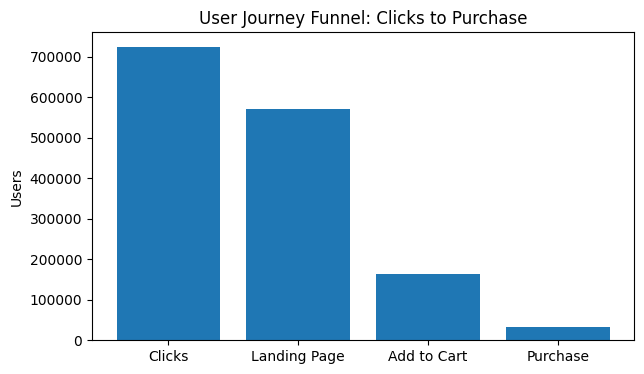

In [ ]:
# funnel (H4) chart representation

stages = ["Clicks", "Landing Page", "Add to Cart", "Purchase"]
counts = [clicks, lpv, cart, purchases]

plt.figure(figsize=(7, 4))
plt.bar(stages, counts)
plt.title("User Journey Funnel: Clicks to Purchase")
plt.ylabel("Users")
plt.show()

In [ ]:
# Platform-wise (H1)

platform = df.groupby("platform")[["impressions", "clicks", "purchases", "ad_spend_inr", "revenue_inr"]].sum()

platform["CTR"] = platform["clicks"] / platform["impressions"] * 100
platform["CVR"] = platform["purchases"] / platform["clicks"] * 100
platform["ROAS"] = platform["revenue_inr"] / platform["ad_spend_inr"]

platform.sort_values("ROAS").round(2)

# H1 Verified (correct): ROAS varies widely across platforms, from 0.64 (LinkedIn) to 11.66 (Email).
# LinkedIn is the only platform with ROAS below 1 (₹0.64 revenue for every ₹1 spent).
# Email (11.66) and Google Ads (4.96) perform best. Facebook (1.50) and YouTube (1.51) also have low ROAS.
# (ROAS is based on revenue, not profit.)

,impressions,clicks,purchases,ad_spend_inr,revenue_inr,CTR,CVR,ROAS
platform,,,,,,,,
LinkedIn,993421,9824,282,1073412.88,684393.17,0.99,2.87,0.64
Facebook,8117011,126152,5362,6195258.94,9312879.29,1.55,4.25,1.50
YouTube,7166142,57472,1482,1726023.96,2601832.29,0.80,2.58,1.51
Instagram,9040295,152728,4886,3795777.26,7918706.51,1.69,3.20,2.09
Google Ads,7149469,312964,17540,6532466.37,32420012.72,4.38,5.60,4.96
Email,1183303,64643,3948,645015.68,7522201.00,5.46,6.11,11.66


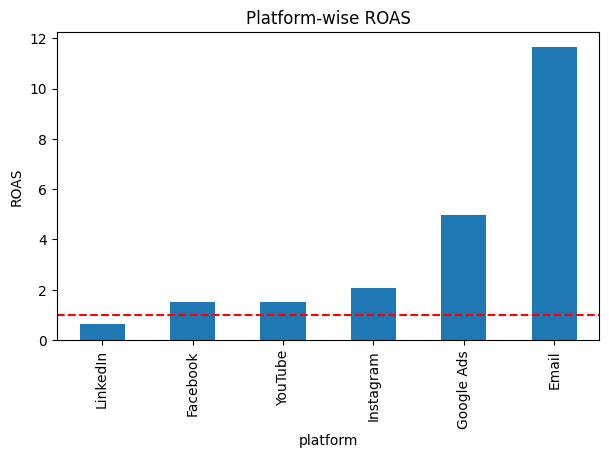

In [ ]:
# H1 chart

platform["ROAS"].sort_values().plot(kind="bar", figsize=(7, 4))
plt.title("Platform-wise ROAS")
plt.ylabel("ROAS")
plt.axhline(1, color="red", linestyle="--")
plt.show()

In [ ]:
# Campaign-wise (H6)

campaign = df.groupby("campaign_name")[["clicks", "purchases", "ad_spend_inr", "revenue_inr"]].sum()

campaign["CVR"] = campaign["purchases"] / campaign["clicks"] * 100
campaign["ROAS"] = campaign["revenue_inr"] / campaign["ad_spend_inr"]
campaign["spend_lakh"] = campaign["ad_spend_inr"] / 100000

campaign[["spend_lakh", "CVR", "ROAS"]].sort_values("ROAS").round(2)

# H6 Verified (correct): Two campaigns have ROAS below 1: LinkedIn Sponsored (0.64) and Facebook Prospecting (0.67).
# Facebook Prospecting received the largest budget (₹49.59 lakh) but generated only ₹33.01 lakh in revenue.
# Email Newsletter Ads is the best-performing campaign (ROAS 11.66).

,spend_lakh,CVR,ROAS
campaign_name,,,
LinkedIn Sponsored,10.73,2.87,0.64
Facebook Prospecting,49.59,2.73,0.67
YouTube Pre-roll,17.26,2.58,1.51
Instagram Reels,26.15,2.96,1.75
Instagram Influencer,11.81,3.64,2.83
Google Search - Generic,27.19,4.38,3.33
Google Shopping,18.13,5.23,4.50
Facebook Retargeting,12.36,6.34,4.86
Google Search - Brand,20.00,7.17,7.60


In [ ]:
# Device-wise (H2)

device = df.groupby("device")[["impressions", "clicks", "purchases", "ad_spend_inr", "revenue_inr"]].sum()

device["CTR"] = device["clicks"] / device["impressions"] * 100
device["CVR"] = device["purchases"] / device["clicks"] * 100
device["ROAS"] = device["revenue_inr"] / device["ad_spend_inr"]
device["spend_share_%"] = device["ad_spend_inr"] / device["ad_spend_inr"].sum() * 100

device[["spend_share_%", "CTR", "CVR", "ROAS"]].round(2)

# H2 Verified (Incorrect): Hypothesis rejected. Mobile CVR (4.67%) and Desktop CVR (4.62%) are almost the same,
# so Mobile CVR is not lower.
# However, Desktop ROAS (3.58) is higher than Mobile ROAS (2.74), even though Mobile has the largest spend share (56.99%).
# The reason is not conversion but differences in CTR, CPC and order value (see the next cell).

,spend_share_%,CTR,CVR,ROAS
device,,,,
Desktop,30.98,2.41,4.62,3.58
Mobile,56.99,2.00,4.67,2.74
Tablet,12.03,2.17,4.47,2.95


In [ ]:
# Why is Desktop ROAS higher than Mobile? Check CPC and AOV

extra = df.groupby("device")[["clicks", "purchases", "ad_spend_inr", "revenue_inr"]].sum()
extra["CPC"] = extra["ad_spend_inr"] / extra["clicks"]
extra["AOV"] = extra["revenue_inr"] / extra["purchases"]
extra[["CPC", "AOV"]].round(2)

# Desktop: CPC ₹24.57, AOV ₹1,907. Mobile: CPC ₹29.65, AOV ₹1,739.
# Desktop clicks are cheaper and orders are larger, so ROAS is higher.
# Desktop CTR is also higher (2.41% vs 2.00%).

,CPC,AOV
device,,
Desktop,24.57,1907.29
Mobile,29.65,1739.22
Tablet,27.22,1800.80


In [ ]:
# Audience-wise (H3)

audience = df.groupby("target_audience")[["clicks", "purchases", "ad_spend_inr", "revenue_inr"]].sum()

audience["CVR"] = audience["purchases"] / audience["clicks"] * 100
audience["ROAS"] = audience["revenue_inr"] / audience["ad_spend_inr"]
audience["spend_share_%"] = audience["ad_spend_inr"] / audience["ad_spend_inr"].sum() * 100

audience[["spend_share_%", "CVR", "ROAS"]].sort_values("ROAS").round(2)

# H3 Verified (correct): Hypothesis validated. Existing Customers deliver a significantly higher CVR (6.78%) compared to New Users (3.70%).
# Existing Customers also achieve the highest ROAS (8.59), while New Users consume the largest spend share (69.27%) with a ROAS of 2.00.

,spend_share_%,CVR,ROAS
target_audience,,,
Professionals,5.38,2.87,0.64
New Users,69.27,3.70,2.00
Lookalike,5.91,3.64,2.83
Website Visitors,6.19,6.34,4.86
Existing Customers,13.25,6.78,8.59


In [ ]:
# Festival (H5)

f = df.groupby("festive")[["impressions", "clicks", "purchases", "ad_spend_inr", "revenue_inr"]].sum()

f["days"] = df.groupby("festive")["date"].nunique()
f["revenue_per_day_lakh"] = f["revenue_inr"] / f["days"] / 100000
f["purchases_per_day"] = f["purchases"] / f["days"]
f["CPM"] = f["ad_spend_inr"] / f["impressions"] * 1000
f["ROAS"] = f["revenue_inr"] / f["ad_spend_inr"]

f[["days", "revenue_per_day_lakh", "purchases_per_day", "CPM", "ROAS"]].round(2)

# H5 Verified (Partially correct): Sales increased during the festive period, but efficiency dropped.
# Revenue per day rose from ₹3.09 lakh to ₹4.42 lakh (+43%) and purchases per day from 170.9 to 246.9 (+44%).
# However, CPM rose from ₹570 to ₹689 (+21%) and ROAS fell from 3.16 to 2.59.
# Higher traffic and spend lifted sales, but higher ad costs reduced the return on each rupee spent.

,days,revenue_per_day_lakh,purchases_per_day,CPM,ROAS
festive,,,,,
False,157,3.09,170.92,569.67,3.16
True,27,4.42,246.85,689.06,2.59
